# 3. Confirm the choice, take it apart, and submit it

The climb (`2-climb.ipynb`) chose `c8s2 r16s2 r32s2 r32 gap`, 40 epochs, 4 views, on split
11. A choice made on some images is a little lucky on exactly those images, so:

1. **Confirm** it on splits 7 and 3, which played no part in choosing.
2. **Ablate** it: remove each part in turn. Did every part earn its place?
3. **Make it train faster** on a CPU, without changing its FLOPs or its accuracy.
4. **Submit** it: write `model.py`, then score it the way GitHub will, on a CPU with
   Python 3.14, and count its compute.

In [1]:
%matplotlib inline
%config InlineBackend.figure_formats = ["png"]
import matplotlib.pyplot as plt
from analyze import mean_se, plot_settings, show, summary

plt.rcParams["figure.dpi"] = 80

## 1. Confirmation on fresh images

3 seeds on each split, 4 views. BuzinD's submission, scored with `uv run score
submissions/BuzinD --split-seed <split>` (one run each): 96.67 (split 11), 97.06 (7),
96.81 (3). The runner-up from experiment 12 (last stage 48 channels) is there for
comparison.

**Prediction:** the choice keeps a lead of about 0.3 points over BuzinD.

In [2]:
show("13-confirm", "12-neighbours")
bar = {11: 96.67, 7: 97.06, 3: 96.81}
for t in summary("13-confirm", "12-neighbours"):
    if t["label"].startswith(("chosen", "last stage 32")):
        split = t["runs_"][0]["split"]
        acc, se = mean_se([100 * r["acc_views"]["4"] for r in t["runs_"]])  # 4 views
        print(
            f"split {split:>2}: ours {acc:.2f} ± {se:.2f} (4 views)   "
            f"BuzinD {bar[split]:.2f}   difference {acc - bar[split]:+.2f}"
        )

experiment    setting                            n    check acc  1 view  train  TFLOP  MFLOP   params  gpu s
13-confirm    chosen (6.5 MF, 40 ep), split 7    3  97.46 ±0.12   96.84  96.01  13.12   25.9    37330    351
13-confirm    chosen (6.5 MF, 40 ep), split 3    3  97.18 ±0.02   96.68  96.09  13.12   25.9    37330    353
13-confirm    runner-up, last stage 48, split 7  3  97.46 ±0.13   96.93  96.31  17.80   34.9    55314    368
13-confirm    runner-up, last stage 48, split 3  3  97.22 ±0.09   96.88  96.30  17.80   34.9    55314    371
12-neighbours last stage 40 (7.6 MF)             3  96.60 ±0.10   96.60  96.25  15.44    7.6    46290    365
12-neighbours last stage 32 (6.5 MF)             3  96.74 ±0.22   96.74  96.25  13.12    6.5    37330    337
12-neighbours last stage 56 (10.0 MF)            3  96.71 ±0.05   96.71  96.49  20.47   10.0    65490    363
12-neighbours middle 24 (7.6 MF)                 3  96.72 ±0.06   96.72  96.24  15.38    7.6    46114    369
12-neighbours first

**Result:** the lead holds on both fresh splits: **+0.40 on split 7** (97.46 vs
97.06) and **+0.37 on split 3** (97.18 vs 96.81), close to the +0.46 seen on split 11:
the choice was not just lucky on its own split. The runner-up ties again on accuracy, at
36% more compute: choosing the cheaper one was right.

## 2. Ablation: did every part earn its place?

Each row removes one part of the choice and changes nothing else (same learning rate,
same epochs), on split 11, where the choice scores 97.13 ± 0.11 with 4 views. Two rows
also show the removal with a rate of 0.02, which suits them better.

**Prediction:** every part is worth something; the schedule and batch norm the most.

experiment    setting                            n    check acc  1 view  train  TFLOP  MFLOP   params  gpu s
14-ablation   no augmentation                    3  95.92 ±0.14   95.04  99.56  13.12   25.9    37330    302
14-ablation   no shifts (symmetries only)        3  96.89 ±0.17   96.32  96.67  13.12   25.9    37330    315
14-ablation   Adam 3e-3 instead of SGD           3  96.41 ±0.26   95.74  95.45  13.12   25.9    37330    356
14-ablation   no residual shortcuts              3  96.43 ±0.14   96.06  95.60  12.84   25.4    36594    285
14-ablation   no batch norm (standardized input), lr 0.02 3  93.61 ±0.05   92.91  93.57  13.12   25.9    37114    259
14-ablation   constant rate 0.02 (no schedule)   3  89.40 ±1.68   88.27  93.24  13.12   25.9    37330    336
14-ablation   no batch norm (standardized input) 3  91.51 ±2.31   90.49  91.39  13.12   25.9    37114    271
14-ablation   constant rate 0.1 (no schedule)    3  83.64 ±5.98   81.91  89.96  13.12   25.9    37330    349


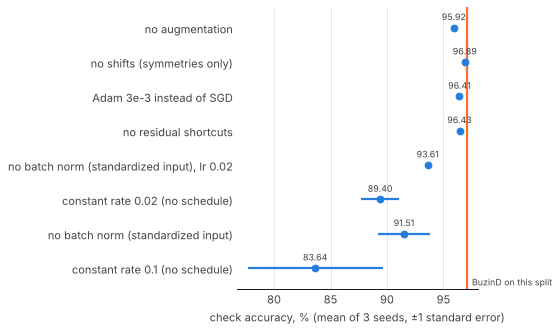

In [3]:
show("14-ablation")
plot_settings("14-ablation", bar=97.13);

(The orange line is the choice itself here, 97.13, not BuzinD.)

**Result:**

| removed | check accuracy | lost | why it mattered |
|---|---|---|---|
| the schedule (constant rate 0.1) | 83.6 ± 6.0 | −9.5 | the end point is a lottery again (exp. 2); 89.4 at a constant 0.02 |
| batch norm (input standardized instead) | 91.5 ± 2.3 | −5.6 | a rate of 0.1 is too high without it; 93.6 at 0.02 |
| augmentation | 95.92 | −1.2 | training accuracy 99.6: it memorizes (exp. 5) |
| SGD (Adam 3e-3 instead) | 96.41 | −0.7 | exp. 8 |
| residual shortcuts | 96.43 | −0.7 | exp. 7 |
| shifts (symmetries kept) | 96.89 | −0.24 | within luck: the 8 symmetries do most of the work |

**Decision:** keep everything. The shifts did not prove their worth here; they cost no
FLOPs and did not hurt, so they stay, but it is worth knowing they are the weakest part.

## 3. Training time

The leaderboard also shows training time. On this computer the choice trained in 170-206 s
and BuzinD's submission in 162-187 s (timings move by ±15% from run to run): a tie, not a
win. Where does the time go? Profiling one training step on the CPU (64 images, 4 cores):

| part of the step | share of the time |
|---|---|
| backward pass (mostly convolutions) | 50% |
| forward pass | 29% |
| augmentation (flips, turns, shifts) | 18% |
| optimizer step | 3% |

and, layer by layer, the time is not where the FLOPs are: the first residual block (32x32
pixels, 8-16 channels, 1.8 MFLOP per image) takes 3 times as long as the last one (8x8, 32
channels, 2.4 MFLOP). Many pixels and few channels keep a CPU busy moving memory, not
computing. Two fixes that change no FLOPs:

1. **A bigger batch:** the same FLOPs in half as many, fuller steps.
2. **Cheaper augmentation:** flips, turns and shifts only move pixels, so they compose
   into a single map of where each pixel comes from: one gather of the uint8 pixels
   instead of five passes over float images. Same random numbers, same images, bit for
   bit (`tests/test_autoresearch.py` checks it), in half the time.

The bigger batch could cost accuracy (experiment 8 found batch 128 worse with Adam).

**Prediction:** batch 128 with the rate doubled (the "linear scaling rule") ties.

experiment    setting                            n    check acc  1 view  train  TFLOP  MFLOP   params  gpu s
15-batch      batch 128, lr 0.1                  3  96.92 ±0.09   96.29  96.22  13.12   25.9    37330     54
15-batch      batch 128, lr 0.2                  3  96.79 ±0.24   96.28  96.25  13.12   25.9    37330     57
15-batch      batch 256, lr 0.2                  3  96.56 ±0.15   95.87  96.09  13.12   25.9    37330     40
15-batch      batch 64, lr 0.1 (the choice)      3  96.85 ±0.17   96.47  96.15  13.12   25.9    37330     77
15-batch      batch 256, lr 0.4                  3  96.08 ±0.24   95.57  95.65  13.12   25.9    37330     30


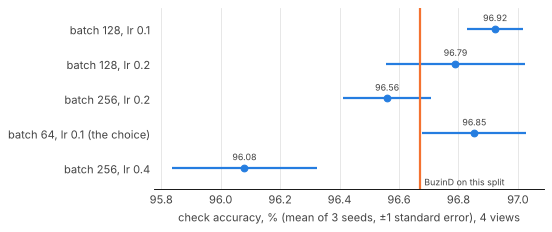

In [4]:
show("15-batch")
plot_settings("15-batch", bar=96.67, views=4);

**Result:** batch 128 ties with batch 64 *at the same rate* (96.92 ± 0.09 vs 96.85 ±
0.17); doubling the rate brings nothing; batch 256 loses (−0.3 and −0.8). On this
computer's CPU, one run each: batch 64 206 s, **batch 128 143 s**, batch 256 144 s
(BuzinD, the same hour: 162 s). Then on the fresh splits:

In [5]:
show("16-confirm-batch", "13-confirm")

experiment    setting                            n    check acc  1 view  train  TFLOP  MFLOP   params  gpu s
16-confirm-batchbatch 128, lr 0.1, split 7         3  97.30 ±0.03   96.60  96.30  13.12   25.9    37330     36
16-confirm-batchbatch 128, lr 0.1, split 3         3  97.01 ±0.23   96.44  96.29  13.12   25.9    37330     36
13-confirm    chosen (6.5 MF, 40 ep), split 7    3  97.46 ±0.12   96.84  96.01  13.12   25.9    37330    351
13-confirm    chosen (6.5 MF, 40 ep), split 3    3  97.18 ±0.02   96.68  96.09  13.12   25.9    37330    353
13-confirm    runner-up, last stage 48, split 7  3  97.46 ±0.13   96.93  96.31  17.80   34.9    55314    368
13-confirm    runner-up, last stage 48, split 3  3  97.22 ±0.09   96.88  96.30  17.80   34.9    55314    371


Split 7: 97.30 (batch 64: 97.46); split 3: 97.01 (97.18); split 11: +0.07. Over
the three splits, −0.09: within luck, and still above BuzinD on every split.

**Decision:** batches of 128 (and the one-gather augmentation): the same accuracy, the same
FLOPs, about 30% less time.

## 4. The submission

Everything above trained with `search.py`, which can describe any network in the climb.
`model.py` is the lean copy of the one setting chosen: about 150 lines, no grammar, no
options GitHub would never use. `tests/test_autoresearch.py` checks that the two train to
the same weights, give the same answers and cost the same compute.

Running the next cell writes `model.py`; GitHub only ever sees that file.

In [6]:
%%writefile model.py
"""autoresearch: a small residual CNN, climbed to from a naive CNN one experiment at a time.

How every choice here was made is in NOTES.md and the notebooks. In short:
- batch norm after every convolution, and a learning rate that warms up, then anneals to
  zero (cosine): batch norm learns fast, the annealing makes the end point stable
- each training image is flipped, turned and shifted at random: a satellite photo has no
  "up", and without this the network memorizes
- a first convolution with stride 2 (the 64x64 layer earned nothing), residual blocks
  (the best block the leaderboard's FLOP counter charges fairly), and global average
  pooling into the classifier
- SGD with Nesterov momentum, which beat Adam by a point at equal compute; batches of 128,
  which train 30% faster on a CPU than 64 for the same accuracy
- a small network trained for long: at equal compute it beat every wider or deeper one
- the answer averages the scores of 4 turned copies of the image
"""

import math
from dataclasses import dataclass

import torch
from torch import nn
from torch.nn import functional as F


@dataclass(frozen=True)
class Config:
    widths: tuple[int, ...] = (8, 16, 32, 32)  # stem, then one residual block per width
    strides: tuple[int, ...] = (2, 2, 2, 1)
    epochs: int = 40
    batch_size: int = 128  # as accurate as 64 (exp. 15-16), and 30% faster on a CPU
    lr: float = 0.1
    momentum: float = 0.9
    weight_decay: float = 5e-4
    warmup: float = 0.1  # share of the steps spent warming up
    shift: int = 4  # random shifts of up to this many pixels
    views: int = 4  # turned copies averaged when answering
    seed: int = 0


def conv_bn(c_in: int, c_out: int, k: int = 3, stride: int = 1, relu: bool = True):
    layers = [nn.Conv2d(c_in, c_out, k, stride, k // 2, bias=False), nn.BatchNorm2d(c_out)]
    return nn.Sequential(*layers, *([nn.ReLU(inplace=True)] if relu else []))


class Residual(nn.Module):
    """Two 3x3 convolutions, added to a shortcut (a 1x1 convolution if the shape changes)."""

    def __init__(self, c_in: int, c_out: int, stride: int) -> None:
        super().__init__()
        self.body = nn.Sequential(
            conv_bn(c_in, c_out, stride=stride), conv_bn(c_out, c_out, relu=False)
        )
        same = stride == 1 and c_in == c_out
        self.skip = nn.Identity() if same else conv_bn(c_in, c_out, 1, stride, relu=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return F.relu(self.body(x) + self.skip(x))


def make_network(cfg: Config) -> nn.Module:
    stem, *rest = cfg.widths
    layers = [conv_bn(3, stem, stride=cfg.strides[0])]
    for c_in, c_out, stride in zip(cfg.widths, rest, cfg.strides[1:], strict=False):
        layers.append(Residual(c_in, c_out, stride))
    layers += [nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(cfg.widths[-1], 10)]
    return nn.Sequential(*layers)


# The 8 symmetries of a square, as (transpose?, dims to flip). The first `views` are used.
SYMMETRIES = [(False, ()), (False, (3,)), (False, (2,)), (False, (2, 3))]
SYMMETRIES += [(True, dims) for _, dims in SYMMETRIES]


class Views(nn.Module):
    """Answer with the average scores of the network over turned copies of the image."""

    def __init__(self, network: nn.Module, views: int) -> None:
        super().__init__()
        self.network = network
        self.views = views

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        total = 0
        for transpose, dims in SYMMETRIES[: self.views]:
            view = x.transpose(2, 3) if transpose else x
            total = total + self.network(view.flip(dims) if dims else view)
        return total / self.views


def augment(images: torch.Tensor, batch: torch.Tensor, shift: int) -> torch.Tensor:
    """The images of a batch, each flipped, turned and shifted at random, as floats.

    The shift fills in by mirroring the edge. All three are moves of pixels, so they are
    composed into one map of where each output pixel comes from, and done as one gather
    of the uint8 pixels: twice as fast as doing them one after the other.
    """
    n, side = len(batch), images.shape[-1]
    flip_w, flip_h, turn = (torch.rand(n, 1, 1) < 0.5 for _ in range(3))
    dy, dx = torch.randint(0, 2 * shift + 1, (2, n, 1)).unbind(0)
    pos = torch.arange(side) - shift

    def mirror(k: torch.Tensor) -> torch.Tensor:  # positions outside the image reflect in
        return torch.where(k < 0, -k, torch.where(k > side - 1, 2 * (side - 1) - k, k))

    rows = mirror(dy + pos)[:, :, None].expand(n, side, side)
    cols = mirror(dx + pos)[:, None, :].expand(n, side, side)
    rows, cols = torch.where(turn, cols, rows), torch.where(turn, rows, cols)
    rows = torch.where(flip_h, side - 1 - rows, rows)
    cols = torch.where(flip_w, side - 1 - cols, cols)
    where_from = (rows * side + cols).view(n, 1, side * side).expand(n, 3, side * side)
    pixels = images[batch].view(n, 3, side * side).float().div_(255)
    return pixels.gather(2, where_from).view(n, 3, side, side)


def train(train_set, log, cfg: Config = Config()) -> nn.Module:
    torch.manual_seed(cfg.seed)
    images, labels = train_set.images, train_set.labels
    network = make_network(cfg)
    optimizer = torch.optim.SGD(
        network.parameters(),
        lr=cfg.lr,
        momentum=cfg.momentum,
        nesterov=True,
        weight_decay=cfg.weight_decay,
    )
    total = math.ceil(len(images) / cfg.batch_size) * cfg.epochs
    warm = round(cfg.warmup * total)

    def factor(step: int) -> float:  # linear warm-up, then cosine down to zero
        if step < warm:
            return (step + 1) / warm
        return 0.5 * (1 + math.cos(math.pi * (step - warm) / max(1, total - warm)))

    schedule = torch.optim.lr_scheduler.LambdaLR(optimizer, factor)
    for _ in range(cfg.epochs):
        network.train()
        loss_sum = torch.zeros(())
        correct = torch.zeros(())
        for batch in torch.randperm(len(images)).split(cfg.batch_size):
            if len(batch) < 2:  # batch norm needs two images
                continue
            x = augment(images, batch, cfg.shift)
            y = labels[batch]
            scores = network(x)
            loss = F.cross_entropy(scores, y)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            schedule.step()
            loss_sum += loss.detach() * len(batch)
            correct += (scores.argmax(1) == y).sum()
        log(
            train_loss=loss_sum.item() / len(images),
            train_accuracy=correct.item() / len(images),
        )
    return Views(network.eval(), cfg.views)

Overwriting model.py


Now score it exactly as `uv run score` does: on this computer's CPU, with Python
3.14, holding back split 7, then a second training run inside the FLOP counter
(`--flops`). It takes about 6 minutes.

In [7]:
!cd ../.. && uv run score submissions/autoresearch --flops


Submission:     autoresearch
Check accuracy: 97.34% (on held-back training images)
Parameters:     37,330
Model size:     151 kB
Training time:  153 seconds
Compute:        13 TFLOP to train
                26 MFLOP per image
Accuracy by class:
  Annual crop             96.7%  ###################
  Forest                 100.0%  ####################
  Herbaceous vegetation   94.5%  ###################
  Highway                 97.4%  ###################
  Industrial              98.6%  ####################
  Pasture                 96.7%  ###################
  Permanent crop          93.3%  ###################
  Residential             99.0%  ####################
  River                   96.4%  ###################
  Sea or lake             99.6%  ####################
Most common mix-ups (true -> answered):
  Herbaceous vegetation -> Permanent crop: 11 images
  Permanent crop -> Herbaceous vegetation: 10 images
  Permanent crop -> Annual crop: 9 images


**On this computer:** 97.34% on split 7 (one run; 3 seeds on the GPU averaged 97.30),
37,330 parameters, 138-153 s of training over three runs; BuzinD's submission, scored
between two of them, trained for 180 s (97.06%). GitHub's computer is about 2.2 times slower: about 300 s, well
inside 10 minutes. The compute is counted on the 17,280 images it trains on here; on all
21,600, GitHub will count 1.25 times as much: **16.4 TFLOP** to train, **26 MFLOP** per image.

| | BuzinD | autoresearch |
|---|---|---|
| check accuracy, split 11 / 7 / 3 (GPU, 4 views) | 96.67 / 97.06 / 96.81 | 96.92 / 97.30 / 97.01 |
| `uv run score`, back to back on this CPU | 97.06%, 180 s | 97.34%, 138 s |
| training compute | 26.2 TFLOP | 16.4 TFLOP (0.63x) |
| compute per image | 119 MFLOP | 26 MFLOP (0.22x) |
| parameters | 174,274 | 37,330 (0.21x) |

Better on all four of the leaderboard's numbers at once: accuracy, training compute,
compute per image, and training time. Its test accuracy will differ
from these: BuzinD's was 0.3 lower on the test images than its average on these three
splits.

## What to take away

The steps that mattered most were not clever:

1. **Normalize, then schedule the learning rate.** Batch norm plus warm-up and cosine
   annealing turned a lottery (83-87%) into a stable 91.5%.
2. **Augment with the symmetries of the data.** Photos from above have no "up": 8 free
   copies of every image stopped the memorizing.
3. **Count FLOPs before you spend them**, and know how your metric counts them.
4. **Find out whether you underfit or overfit**, from the curves, and act on that:
   regularizers did not help an underfitting network; better optimization (SGD) did.
5. **Compare at equal compute.** Given a fixed budget, a small network trained longer
   beat every bigger one trained less.
6. **Time is not FLOPs.** Profile before optimizing: here the CPU's time went to big,
   thin layers and to augmentation, and a bigger batch and one gather fixed most of it.
7. **Choose on one split, confirm on others; among ties, take the cheapest.**